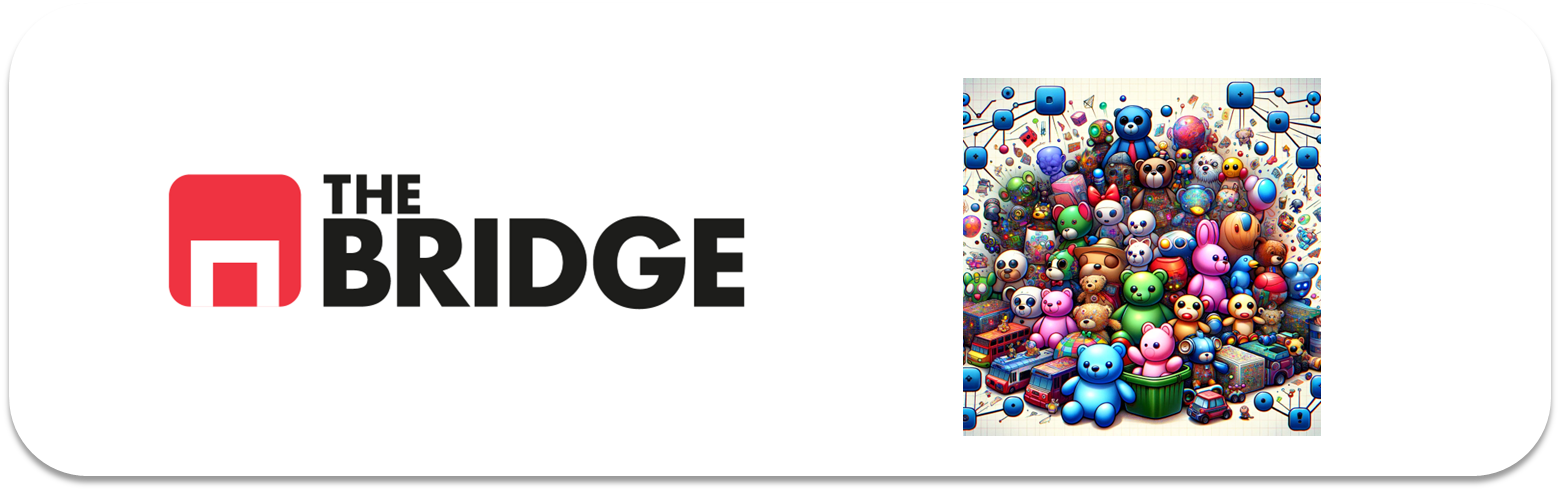

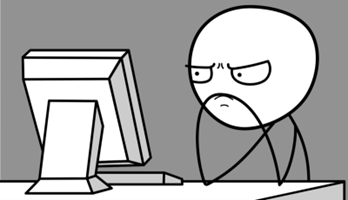

Para ejercitarte y afianzar lo aprendido sobre **DBSCAN**, completa los siguientes ejercicios. Recuerda que necesitarás los datos del directorio `data` de la unidad (`../data`).

Ya tienes las soluciones: intenta no mirarlas de primeras, pero no dejes de hacerlo cuando hayas terminado, por si te pudieran aportar.

### Problema y "justificación": DBSCAN

Como sabemos, existen diversas técnicas de clusterización comprendidas por algoritmos de machine learning no supervisados, cuya finalidad es agrupar distintos elementos de un conjunto de datos sin necesidad de estar previamente etiquetados. 

Anteriormente utilizamos K-Means; sin embargo, este algoritmo tiene algunas limitaciones, como el hecho de que no siempre es sencillo obtener el número óptimo de clusters (k) o que algunas distribuciones de datos no se ajustan a la agrupación por clusters debido a la naturaleza del algoritmo. Para estos casos existen diversos algoritmos de clusterización. 

A continuación, vamos a utilizar el algoritmo DBSCAN (Density-Based Spatial Clustering of Applications with Noise) para capturar grupos en datos con patrones relativamente complejos.

Utilizaremos datos de clientes (establecimientos y empresas) de un distribuidor al por mayor, en los que cada fila recoge el gasto anual de un cliente en distintas categorías de productos (aunque no se incluye el identificador del establecimiento). El objetivo es obtener agrupaciones interesantes de clientes con patrones de compra parecidos:

Features:

    1) FRESH: Gastos en productos frescos;
    2) MILK: Gastos en productos lácteos;
    3) GROCERY: Gastos en comestibles;
    4) FROZEN: Gastos en congelados;
    5) DETERGENTS_PAPER: Gastos en detergentes y derivados del papel;
    6) DELICATESSEN: Gastos en comestibles finos;
    7) CHANNEL: Canal del cliente: Horeca (hoteles, restaurantes y cafeterías) o Retail (venta al por menor);
    8) REGION: Región del cliente;

Fuente: https://archive.ics.uci.edu/ml/datasets/Wholesale+customers

### Ejercicio 0

Importa los paquetes y módulos que necesites a lo largo del notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler


### Ejercicio 1

Carga los datos y haz una primera exploración, incluyendo una descripción de las variables numéricas.

In [2]:
df_wholesale_customers = pd.read_csv('../data/wholesale-customers-data.csv')

In [3]:
df_wholesale_customers.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [4]:
df_wholesale_customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [5]:
df_wholesale_customers.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


*Los datos están bastante limpios y no tenemos valores nulos; sin embargo, al observar los máximos de varias columnas como Fresh, Grocery y otras, detectamos valores muy por encima de la media o de los percentiles. Hagamos un análisis un poco más detallado...*

$$***$$

Es hora de hacer un miniEDA. En clustering, su objetivo no es seleccionar features para predecir un target (que no tenemos), sino intuir posibles agrupaciones y su número, y detectar si hay que transformar y escalar las variables (y cómo).

### Ejercicio 2



Pinta el histograma de las variables y determina cuáles podríamos considerar numéricas continuas y cuáles numéricas discretas (o categóricas).

array([[<Axes: title={'center': 'Channel'}>,
        <Axes: title={'center': 'Region'}>,
        <Axes: title={'center': 'Fresh'}>],
       [<Axes: title={'center': 'Milk'}>,
        <Axes: title={'center': 'Grocery'}>,
        <Axes: title={'center': 'Frozen'}>],
       [<Axes: title={'center': 'Detergents_Paper'}>,
        <Axes: title={'center': 'Delicassen'}>, <Axes: >]], dtype=object)

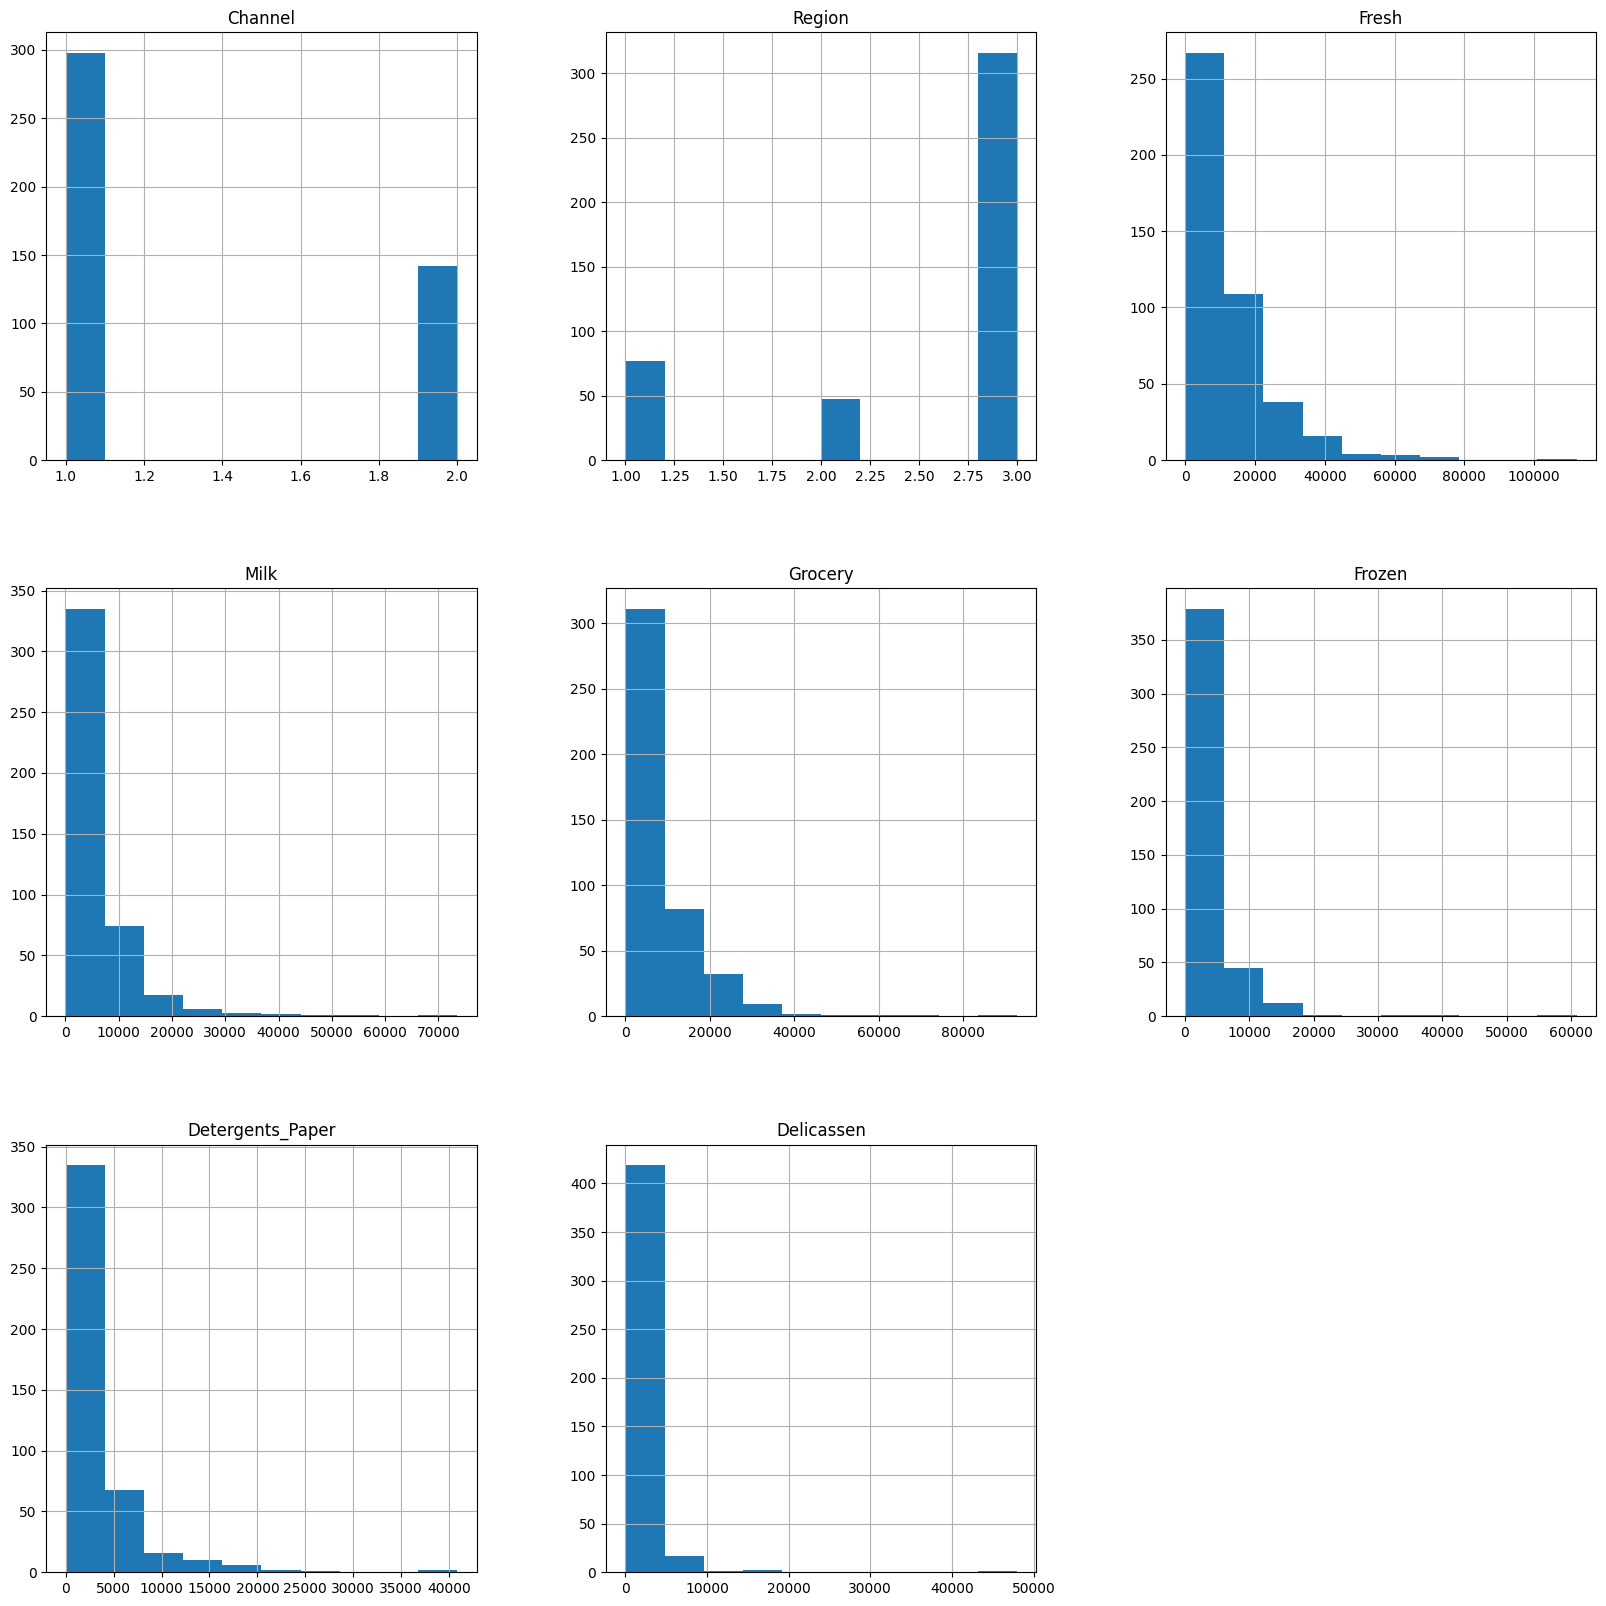

In [6]:
df_wholesale_customers.hist(figsize=(20,20))

In [7]:
features_cat = ["Channel","Region"]
features_num = [col for col in df_wholesale_customers if col not in features_cat]

*Como era de esperar, teniendo en cuenta las definiciones de cada variable o columna, "Channel" y "Region" son asimilables a categóricas y el resto son numéricas continuas.*  
*Así de primeras podríamos considerar que hay que aplicar transformaciones a todas las variables, pero merece la pena analizar un poco más... vamos al siguiente ejercicio (NOTA: Es probable que no veas por qué merece la pena analizar más antes de transformar, pero eso tiene que ver con el conocimiento de dominio, ya que las ventas están agrupadas para los dos canales y no es lo mismo vender al sector hostelero que a los supermercados y tiendas de alimentos)*

### Ejercicio 3

Antes de decidir sobre las agrupaciones, vamos a pintar los histogramas pero separando por canal (ya que es un elemento muy diferenciador del tipo de venta que se realiza a mayorista). Muestra gráficamente para cada variable numérica su histograma para cada canal (Horeca y Retail). 

*Empleando un método directo y no con funciones, como podríamos haber hecho con bootcampviztools, para que tengas otras versiones...*

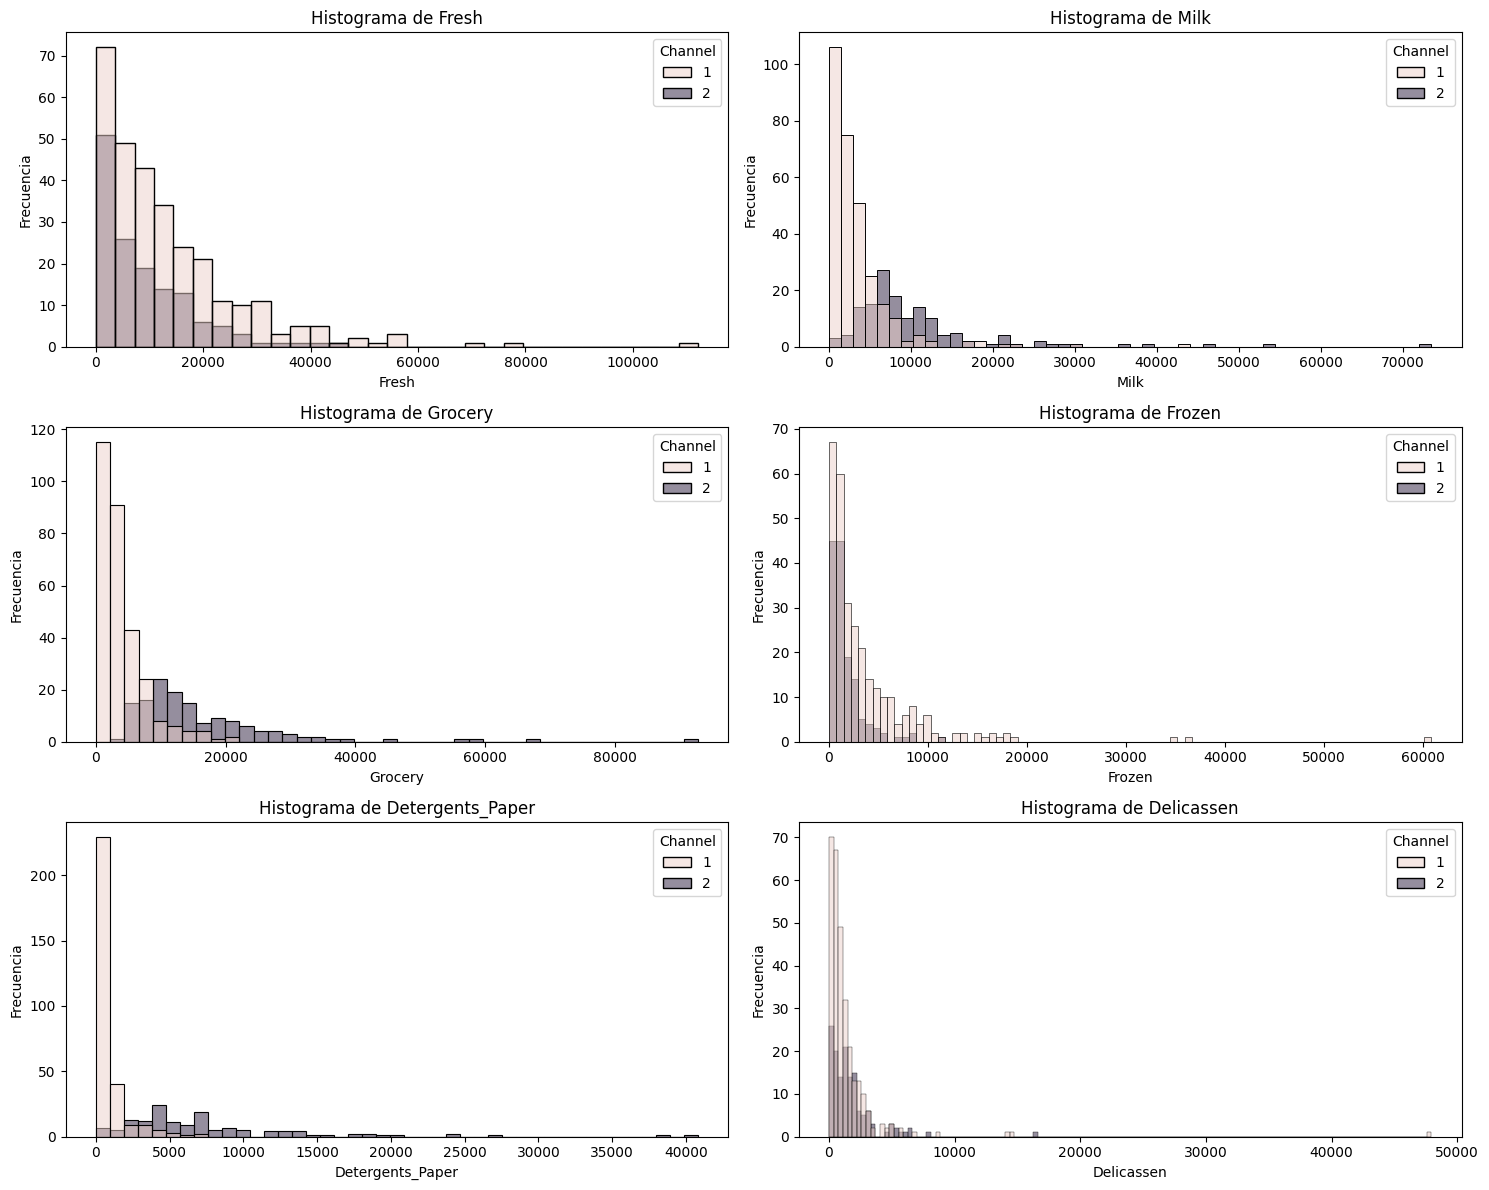

In [8]:
columns = df_wholesale_customers.columns[2::]  # Columnas numéricas
n_cols = len(columns) # Número de columnas a pintar

# Calcular cuántas filas necesitaremos, asumiendo 2 columnas (subplots) por fila
n_rows = n_cols // 2 if n_cols % 2 == 0 else (n_cols // 2) + 1

# Configurar el tamaño de la figura para acomodar todos los subplots
plt.figure(figsize=(15, n_rows * 4))  # Ajusta el tamaño según el número de filas, altura por fila

for i, column in enumerate(columns):
    plt.subplot(n_rows, 2, i + 1)  # Crea subplots en una cuadrícula de n_rows x 2
    sns.histplot(data=df_wholesale_customers, x=column, hue='Channel')
    plt.title(f'Histograma de {column}')
    plt.xlabel(column)
    plt.ylabel('Frecuencia')

plt.tight_layout()  # Ajusta automáticamente los subplots para que encajen en la figura
plt.show()

*Si nos quedáramos solo con los histogramas del ejercicio anterior, transformaríamos todas las columnas. Separando por canal se ve que algunas variables (como "Milk", "Grocery" o "Detergents_Paper") no están tan concentradas a la izquierda en uno de los canales, aunque sigan teniendo una cola larga.*  

*Otro elemento que podemos ver es que las distribuciones son diferentes en varios productos, lo que invita a hacer una agrupación o clustering diferente por "Channel".*

### Ejercicio 4

Analicemos los outliers. Obtén los outliers a partir de los diagramas de boxplot para todos los datos y luego separados por canal.

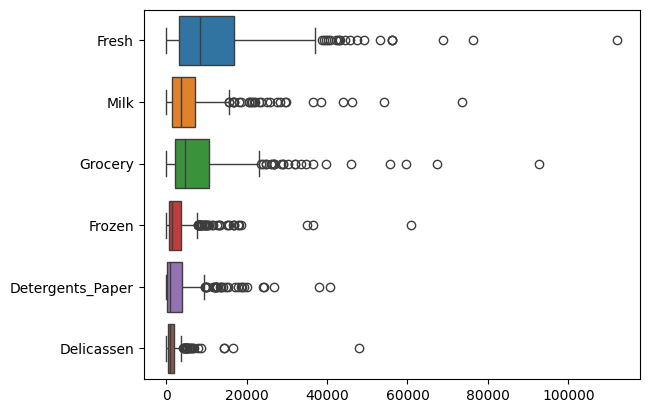

In [9]:
# Visualizando outliers con boxplot
sns.boxplot(df_wholesale_customers[features_num], orient='h');

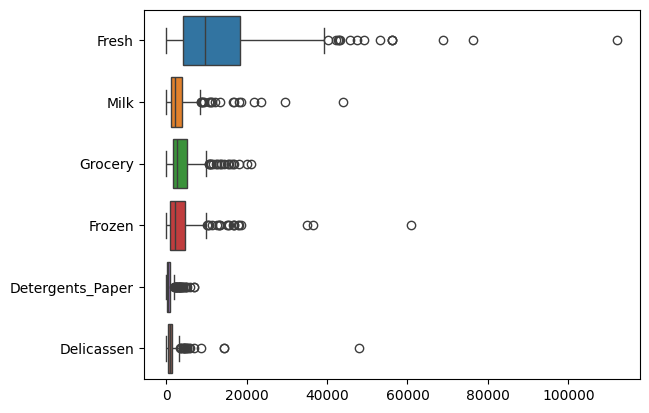

In [10]:
# Para HORECA
sns.boxplot(df_wholesale_customers[df_wholesale_customers.Channel == 1][features_num], orient='h');

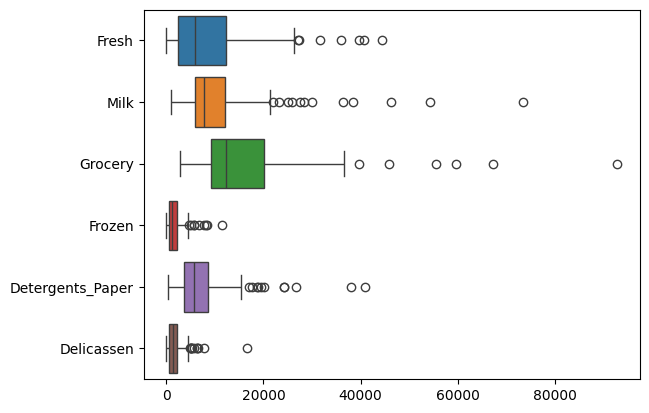

In [11]:
# Para Retail
sns.boxplot(df_wholesale_customers[df_wholesale_customers.Channel == 2][features_num], orient='h');

*Hay outliers significativos en todas ellas y para los dos canales (que también podíamos observar en los histogramas), por lo que cualquier clustering basado en distancias (o sea, todos los que hemos visto) va a necesitar que escalemos, pero antes...*

### Ejercicio 5

Vamos a intentar detectar posibles agrupaciones en los datos con variables dos a dos. Utiliza un pairplot de sns para mostrar los scatter plots de las variables numéricas dos a dos para intentar visualizar algún clustering e incluso justificar el uso de K-Means o DBSCAN. En este ejercicio hazlo para todo el dataset.

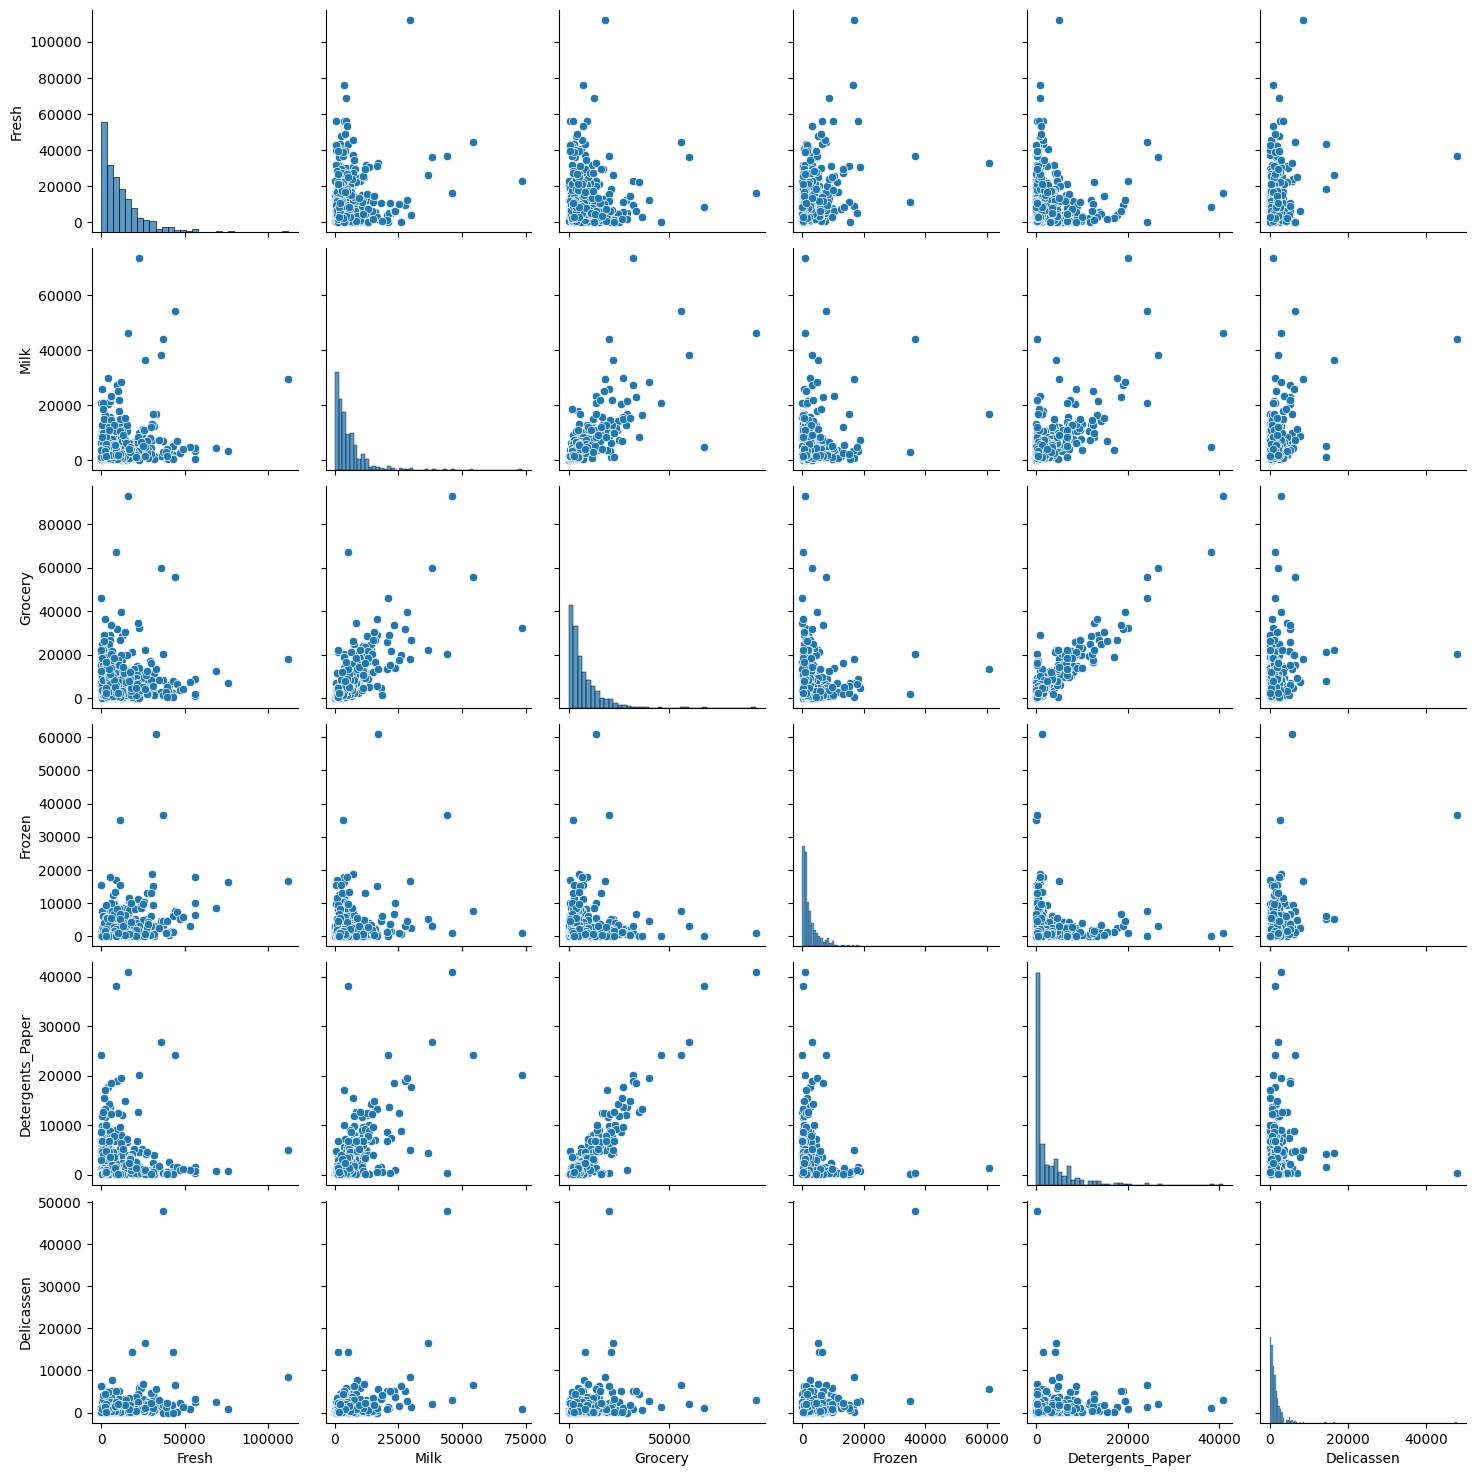

In [12]:
sns.pairplot(df_wholesale_customers[features_num])

*Así tal cual no se ven agrupaciones claras (no hay "manchurrones" separados, son trazos) para un K-Means; de hecho, tampoco se ven zonas separadas en densidad (zonas de puntos, aunque irregulares, separadas por zonas blancas, aunque el tamaño del gráfico influye). Así tal cual no pinta bien para ningún algoritmo.*

### Ejercicio 6

Repite el ejercicio 5 pero separando por canal. Emplea el argumento hue del pairplot para no tener que hacer dos pairplots diferentes. 

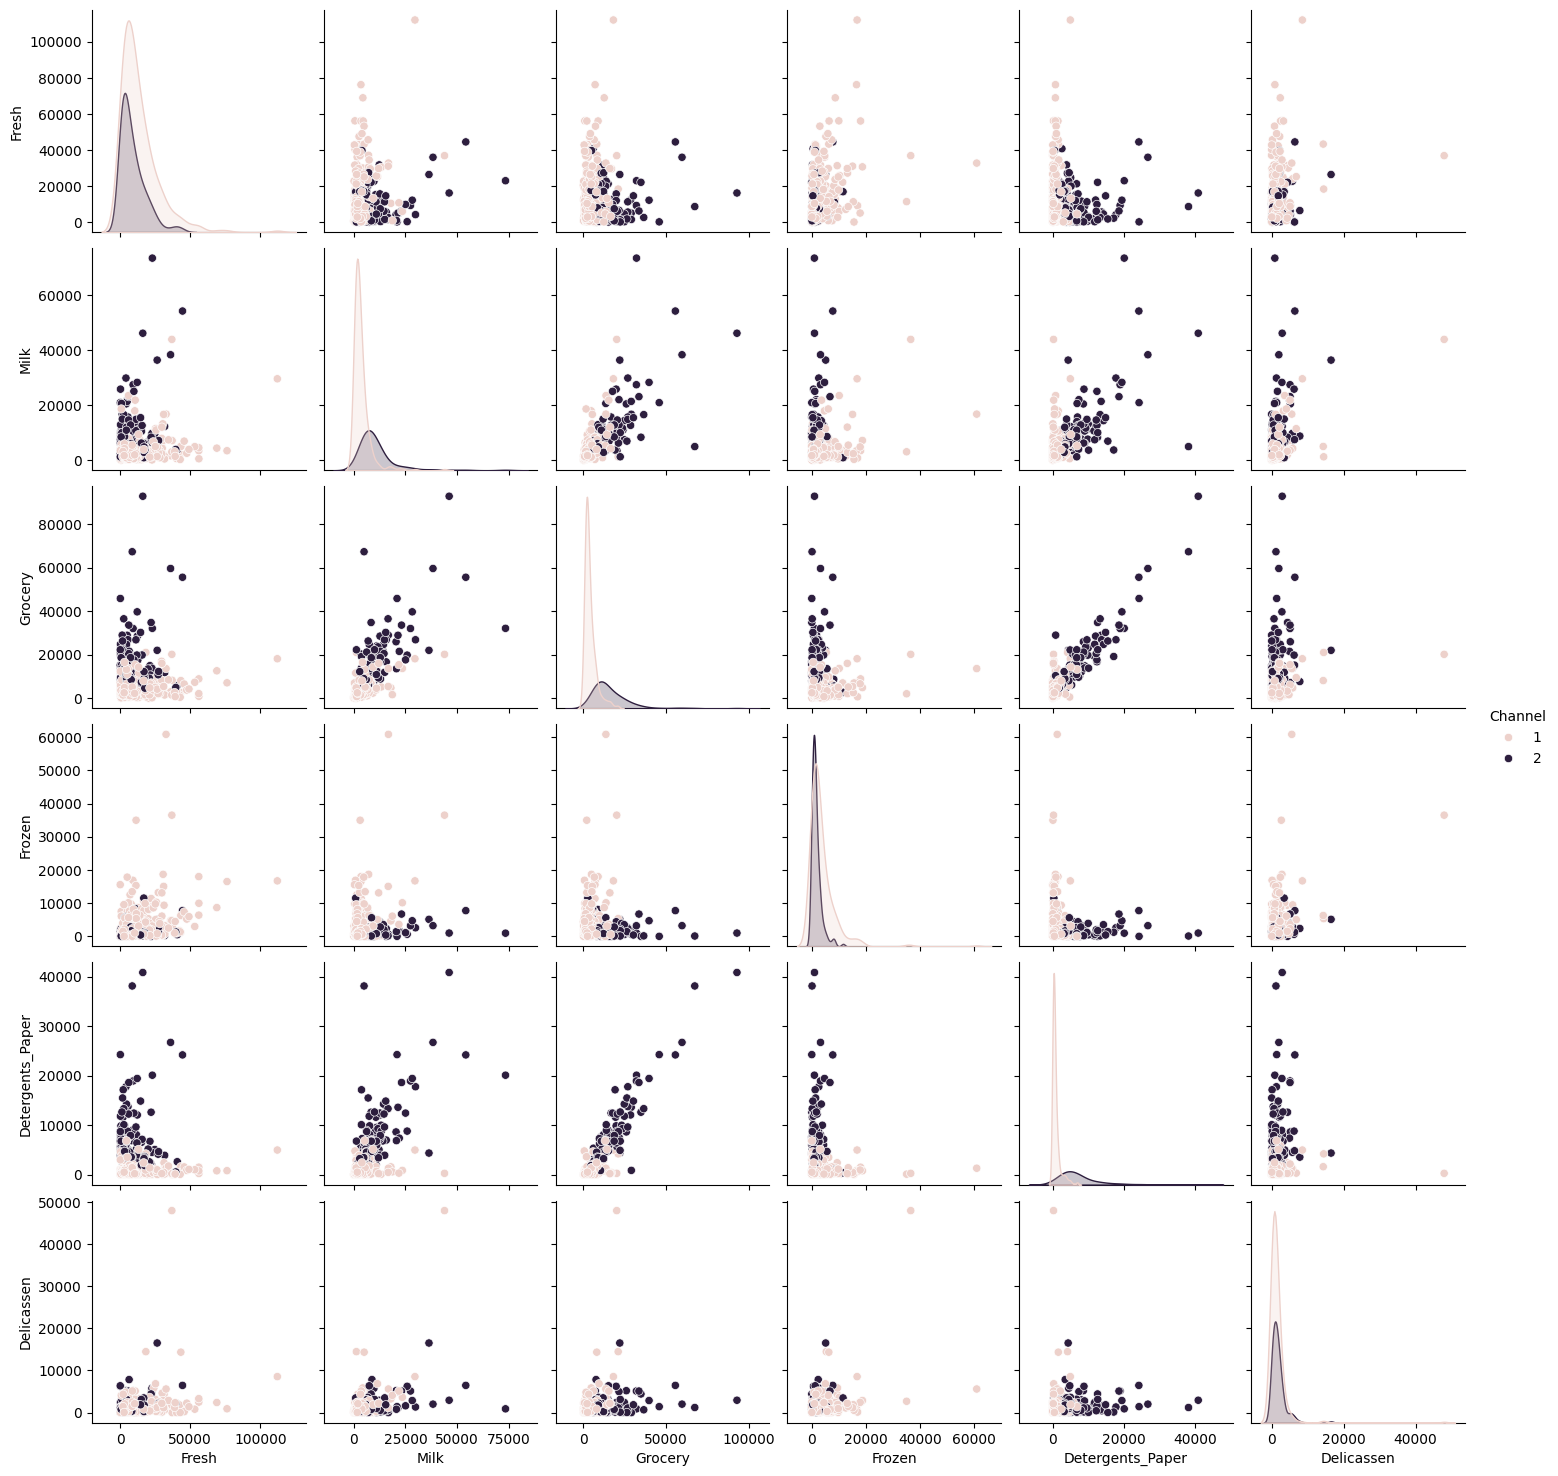

In [13]:
sns.pairplot(df_wholesale_customers[features_num + ["Channel"]], hue = "Channel")

*Como se podía intuir, pero solo eso, sí que parece haber dos regiones de puntos según el canal (fíjate, por ejemplo, en Fresh y Grocery: columna 1, fila 3 empezando por arriba): hay dos regiones, una inferior para el canal 1 (Horeca) y otra superior para el canal 2 (Retail). Pero también puedes ver que están demasiado juntas como para que K-Means consiga separarlas tal cual. En estos casos, tiene mejor pinta usar DBSCAN.*

*En otras palabras, al contrastar los scatter plots podemos empezar a intuir que un clustering con K-Means podría no ser lo más conveniente por la distribución de los datos: no se observan los típicos focos de agrupación (círculos o "blobs") que solemos buscar con K-Means, sino un patrón más irregular. Otro factor a considerar es la presencia de múltiples outliers: DBSCAN suele ser robusto ante outliers y ruido, ya que no los obliga a formar parte de un cluster.*

### Ejercicio 7

Si has logrado hacer los dos ejercicios anteriores (y, si no, consulta su solución), tendrás una idea un poco más clara de por qué puede ser más interesante la clusterización con DBSCAN que con K-Means. Así que vamos a utilizarlo, pero antes escalemos los datos, transformándolos primero (de primeras no vamos a distinguir entre canales, hazlo con todo el dataset). Es decir, aplica la transformación que creas necesaria en las columnas numéricas que creas conveniente. Hazlo en un dataframe copiado del original para poder interpretar los valores correctamente al final.

In [14]:
df_wholesale_customers_scal = df_wholesale_customers.copy()

array([[<Axes: title={'center': 'Fresh'}>,
        <Axes: title={'center': 'Milk'}>],
       [<Axes: title={'center': 'Grocery'}>,
        <Axes: title={'center': 'Frozen'}>],
       [<Axes: title={'center': 'Detergents_Paper'}>,
        <Axes: title={'center': 'Delicassen'}>]], dtype=object)

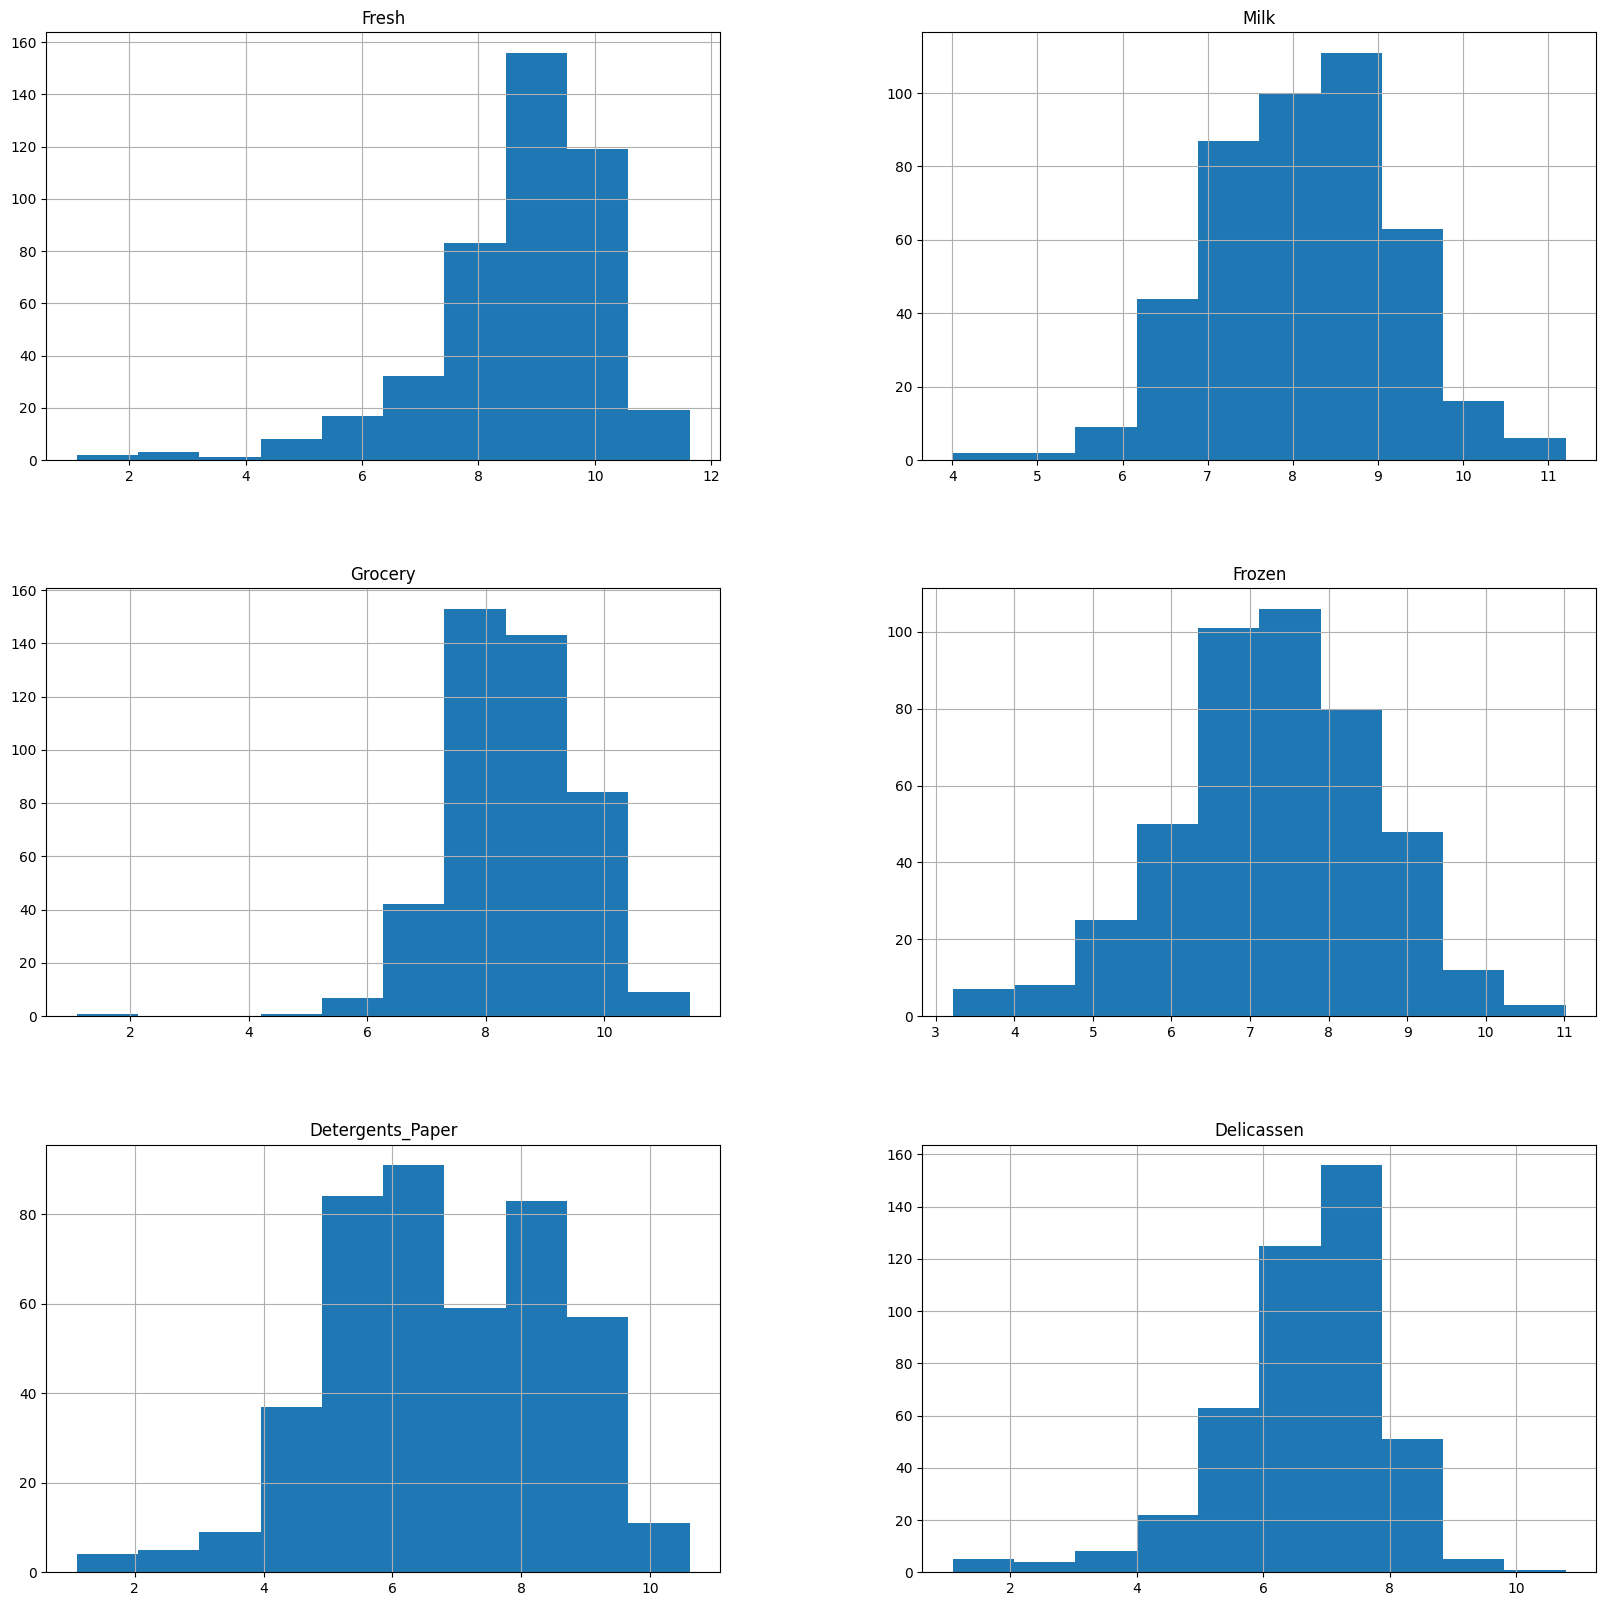

In [15]:
df_wholesale_customers_scal[features_num] = df_wholesale_customers_scal[features_num].apply(np.log) # Según el describe del ejercicio 1 todos los valores mínimos están por encima de 0
df_wholesale_customers_scal[features_num].hist(figsize=(20,20))
    
    

### Ejercicio 8

Escala las variables de gasto (las numéricas continuas), que serán nuestras features. Deja fuera `Channel` y `Region`: son categóricas y, como veremos en el ejercicio 12, incluirlas tal cual distorsiona el clustering.

In [16]:
scaler = StandardScaler()
X_scal = scaler.fit_transform(df_wholesale_customers_scal[features_num]) # Solo las variables de gasto: Channel y Region son categóricas

### Ejercicio 9

En el caso de los modelos no supervisados, una vez hemos tratado las features hay que escoger los hiperparámetros. En el caso de DBSCAN no es el número de clústeres, sino la distancia `eps` que determina el vecindario de un punto y el número de vecinos a partir del cual se decide si una instancia es core o no (`min_samples`). 

Una forma de hacerlo es iterar sobre rangos de estos dos hiperparámetros midiendo el porcentaje de "anomalías" que detecta y considerando como punto de parada un valor por debajo del 10%.

NOTA: Usa un rango de valores de `eps` de 0.001 a 3 y, para `min_samples`, un valor orientativo de 2 veces el número de features empleadas.

In [17]:
outlier_percent = []
min_samples = 2 * X_scal.shape[1] # 2 veces el número de features (6) -> 12

for eps in np.linspace(0.001, 3, 50): # Genera 50 valores equidistantes entre 0.001 y 3

    # Creamos el modelo
    dbscan = DBSCAN(eps = eps, min_samples = min_samples) # min_samples: 2 por dimensión del hiperespacio en el que representamos los puntos... No le des muchas vueltas, es un número muy orientativo. Pero piensa que si fuera una recta querrías 2 valores, un plano 4, un cubo 6...
    dbscan.fit(X_scal)

    # Registramos el porcentaje de anomalías (recuerda que se etiquetan como -1)
    perc_outliers = 100 * np.sum(dbscan.labels_ == -1) / len(dbscan.labels_)

    outlier_percent.append(perc_outliers)

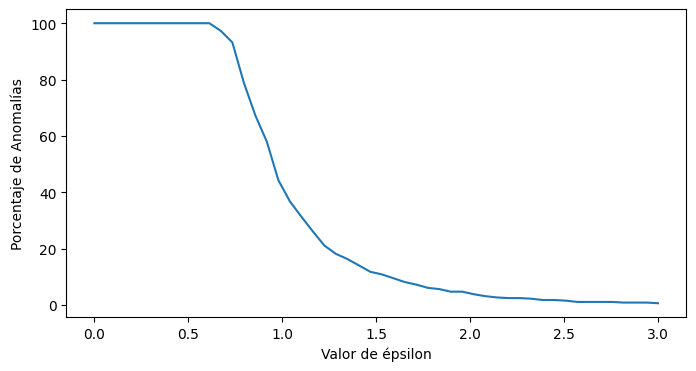

In [18]:
#Vamos a pintar ahora el porcentaje de anomalías vs el valor de eps probado
plt.figure(figsize = (8,4), dpi = 100)
sns.lineplot(x=np.linspace(0.001,3,50),y=outlier_percent)
plt.ylabel("Porcentaje de Anomalías")
plt.xlabel("Valor de épsilon")
plt.show()

*Aplicamos una estimación tipo "codo": el porcentaje de anomalías baja del 10% a partir de eps ≈ 1.6 y después sigue bajando cada vez más despacio. Veamos los valores entre 1.5 y 2.2:*

In [19]:
for indice,eps in [(indice,val) for indice,val in enumerate(np.linspace(0.001,3,50)) if 1.5 <= val <= 2.2]:
    print(f"Para {eps}: {outlier_percent[indice]}% de anomalías")

Para 1.5311020408163265: 10.909090909090908% de anomalías
Para 1.5923061224489796: 9.545454545454545% de anomalías
Para 1.6535102040816325: 8.181818181818182% de anomalías
Para 1.7147142857142856: 7.2727272727272725% de anomalías
Para 1.7759183673469388: 6.136363636363637% de anomalías
Para 1.8371224489795916: 5.681818181818182% de anomalías
Para 1.8983265306122448: 4.7727272727272725% de anomalías
Para 1.9595306122448979: 4.7727272727272725% de anomalías
Para 2.020734693877551: 3.8636363636363638% de anomalías
Para 2.081938775510204: 3.1818181818181817% de anomalías
Para 2.1431428571428572: 2.727272727272727% de anomalías


*A partir de eps ≈ 1.9 (por debajo del 5% de anomalías) la velocidad de decrecimiento se ralentiza bastante, así que cualquier valor a partir de ahí es interesante. Por coger uno redondo, nos quedamos con 2.*

### Ejercicio 10

Entrena un clustering DBSCAN con el valor que hayas encontrado como mejor en el ejercicio anterior (si no has visto claramente un valor, usa eps = 2) y `min_samples` a dos veces el número de features empleadas.

In [20]:
dbscan = DBSCAN(eps = 2, min_samples = min_samples) # min_samples = 12
dbscan.fit(X_scal)

,"eps eps: float, default=0.5The maximum distance between two samples for one to be consideredas in the neighborhood of the other. This is not a maximum boundon the distances of points within a cluster. This is the mostimportant DBSCAN parameter to choose appropriately for your data setand distance function. Smaller values generally lead to more clusters.",2
,"min_samples min_samples: int, default=5The number of samples (or total weight) in a neighborhood for a point tobe considered as a core point. This includes the point itself. If`min_samples` is set to a higher value, DBSCAN will find denser clusters,whereas if it is set to a lower value, the found clusters will be moresparse.",12
,"metric metric: str, or callable, default='euclidean'The metric to use when calculating distance between instances in afeature array. If metric is a string or callable, it must be one ofthe options allowed by :func:`sklearn.metrics.pairwise_distances` forits metric parameter.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors for DBSCAN... versionadded:: 0.17 metric *precomputed* to accept precomputed sparse matrix.",'euclidean'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function... versionadded:: 0.19",None
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'The algorithm to be used by the NearestNeighbors moduleto compute pointwise distances and find nearest neighbors.'auto' will attempt to decide the most appropriate algorithmbased on the values passed to :meth:`fit` method.See :class:`~sklearn.neighbors.NearestNeighbors` documentation fordetails.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or cKDTree. This can affect the speedof the construction and query, as well as the memory requiredto store the tree. The optimal value dependson the nature of the problem.",30
,"p p: float, default=NoneThe power of the Minkowski metric to be used to calculate distancebetween points. If None, then ``p=2`` (equivalent to the Euclideandistance). When p=1, this is equivalent to Manhattan distance.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
"components_ components_: ndarray of shape (n_core_samples, n_features)Copy of each core sample found by training.","ndarray[float64](392, 6)","[[ 0.48, 0.98, 0.44,-1.51, 0.64, 0.41], [ 0.09, 0.99, 0.65, 0.13, 0.76, 0.62], [ 0.02, 0.89, 0.45, 0.38, 0.8 , 1.76], ..., [ 1.25,-0.79,-1.62, 0.87,-1.31, 0.84], [ 0.58, 1.41, 1.68,-0.95, 1.64, 0.66], [ 0.34,-0.49,-0.66,-0.28,-0.97, 0.76]]"
"core_sample_indices_ core_sample_indices_: ndarray of shape (n_core_samples,)Indices of core samples.","ndarray[int64](392,)","[ 0, 1, 2,...,436,437,438]"


In [21]:
dbscan.min_samples

12

### Ejercicio 11

Agrega las etiquetas generadas con DBSCAN a tu dataframe original e interpreta los resultados (observa el número de etiquetas y recuerda que -1 no es un cluster, sino las anomalías u outliers). Luego contesta: ¿qué grupos o patrones fue capaz de capturar DBSCAN? (Haz, por ejemplo, las tablas de contingencia de las etiquetas con las dos variables categóricas por separado y, a partir de ahí, justifica tu respuesta.)

*Analizamos las etiquetas:*

In [22]:
df_wholesale_customers['Labels'] = dbscan.labels_
df_wholesale_customers['Labels'].value_counts()

Labels
 0    423
-1     17
Name: count, dtype: int64

*Solo ha encontrado un clúster (el 0) y 17 anomalías (-1), un 3,9% de los clientes. Es decir, DBSCAN no encuentra zonas densas separadas entre sí: la gran mayoría de los clientes forman una única nube densa.*

*Comprobemos si las anomalías tienen algo que ver con la región o con el canal:*

In [23]:
# Para Region

pd.crosstab(df_wholesale_customers["Labels"], df_wholesale_customers["Region"])

Region,1,2,3
Labels,,,
-1,1,1,15
0,76,46,301


In [24]:
# Para Channel

pd.crosstab(df_wholesale_customers["Labels"], df_wholesale_customers["Channel"])

Channel,1,2
Labels,,
-1,13,4
0,285,138


*Las anomalías se reparten entre canales y regiones de forma parecida al conjunto de los datos (no hay un canal ni una región que las concentre especialmente), así que DBSCAN no ha capturado ninguno de esos grupos. Visto de otra forma:*

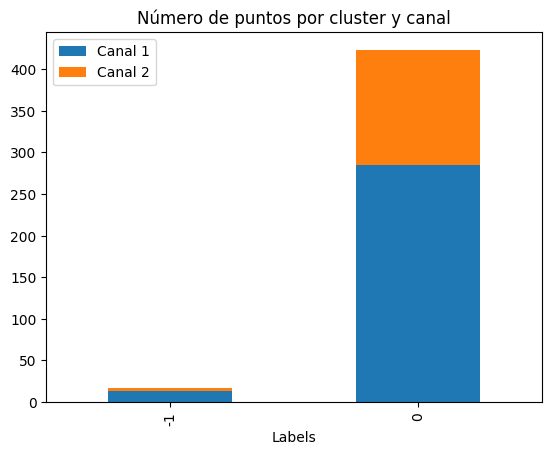

In [25]:
ax = pd.DataFrame(df_wholesale_customers[['Labels', 'Channel']].groupby('Labels').value_counts()).unstack().plot(kind='bar', stacked=True, title='Número de puntos por cluster y canal')
ax.legend(['Canal 1', 'Canal 2']);

*¿Qué tienen de especial entonces las anomalías? Comparemos la mediana del gasto en cada categoría:*

In [26]:
df_wholesale_customers.groupby('Labels')[features_num].median()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Labels,,,,,,
-1,503.0,2616.0,7417.0,469.0,836.0,110.0
0,8635.0,3648.0,4740.0,1593.0,813.0,993.0


*CONCLUSIÓN: Con las variables de gasto, DBSCAN no encuentra varios grupos de clientes, sino un único grupo denso y un 4% de clientes "raros". Si miramos sus medianas, las anomalías son sobre todo clientes con un gasto muy bajo en alguna categoría (por ejemplo, Fresh, Frozen o Delicassen): al aplicar el logaritmo, los valores muy pequeños quedan muy lejos del resto.*

*En este dataset, DBSCAN nos sirve más como detector de clientes atípicos que como segmentador. Para buscar segmentos, podríamos hacer un clustering por separado dentro de cada canal, o probar un K-Means y analizar si sus grupos tienen sentido para el negocio.*

### Ejercicio 12 (EXTRA)

Repite el clustering, pero esta vez escalando e incluyendo también `Channel` y `Region` como features (junto con las variables de gasto ya transformadas). Entrena un DBSCAN con `eps = 2` y `min_samples` igual a 2 veces el número de features, y haz la tabla de contingencia de las etiquetas con `Channel`. ¿Qué ocurre? ¿Por qué?

In [27]:
X_scal_todas = StandardScaler().fit_transform(df_wholesale_customers_scal) # Ahora incluye también Channel y Region

dbscan_todas = DBSCAN(eps = 2, min_samples = 2 * X_scal_todas.shape[1]) # 2 x 8 features = 16
dbscan_todas.fit(X_scal_todas)

pd.crosstab(dbscan_todas.labels_, df_wholesale_customers["Channel"])

Channel,1,2
row_0,,
-1,24,10
0,0,132
1,274,0


*Ahora DBSCAN "encuentra" dos clústeres que coinciden exactamente con los dos canales (aparte de las anomalías). Parece un gran descubrimiento, pero es un artefacto. Veamos a qué distancia quedan los dos canales una vez estandarizada la variable `Channel`:*

In [28]:
canal_escalado = X_scal_todas[:, 0] # Channel es la primera columna
canal_escalado.max() - canal_escalado.min()

2.138948717573628

*Los dos valores de `Channel` quedan a más de 2 unidades de distancia, más que `eps = 2`. Así que dos clientes de canales distintos nunca pueden ser vecinos, y DBSCAN los separa por construcción, sea cual sea su gasto.*

*Moraleja: cuidado al meter variables categóricas (sobre todo binarias) escaladas en un clustering basado en distancias, porque pueden dominar el resultado. Y, en cualquier caso, si ya conocemos el canal, un clustering que solo lo "redescubre" no nos aporta nada.*